In [2]:
from ultralytics import YOLO

# Load a YOLO26 monocular depth model
model = YOLO("yolo26n-depth.pt")

# Predict a depth map for one image
results = model("sfm1.png")
result = results[0]

# Per-pixel depth in meters, at the original image's resolution
depth = result.depth.data
print(f"Nearest {depth.min():.1f} m, farthest {depth.max():.1f} m")

# Save a colorized depth map blended over the photo
result.save(filename="depth_result1.jpg")


image 1/1 c:\CNN-building-components-detector-classifier\sfm1.png: 768x768 depth 0.43-0.94m, 6.6ms
Speed: 1.4ms preprocess, 6.6ms inference, 0.1ms postprocess per image at shape (1, 3, 768, 768)
Nearest 0.4 m, farthest 0.9 m


'depth_result1.jpg'

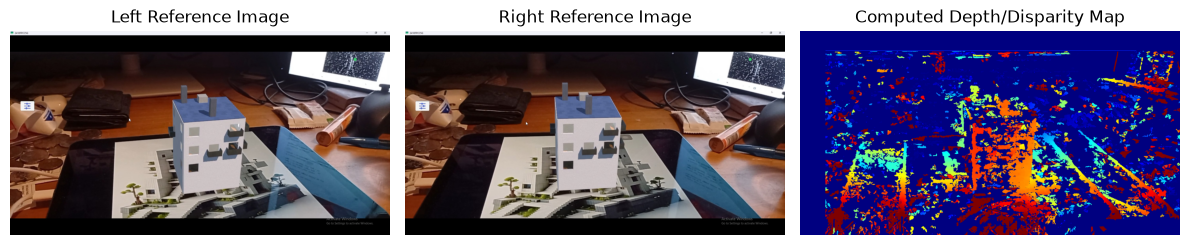

In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

def compute_disparity_map(left_img_path, right_img_path):
    # 1. Load the images in grayscale
    # Stereo matching algorithms strictly require single-channel images
    imgL = cv2.imread(left_img_path, cv2.IMREAD_GRAYSCALE)
    imgR = cv2.imread(right_img_path, cv2.IMREAD_GRAYSCALE)

    if imgL is None or imgR is None:
        raise FileNotFoundError("Could not read one or both input images. Check your file paths.")

    # 2. Configure StereoSGBM parameters
    # Adjust these based on your image resolution and depth requirements
    block_size = 9          # Matched block size (must be an odd number >= 1)
    min_disp = 0            # Minimum possible disparity value
    num_disp = 16 * 8       # Max disparity minus min disparity (must be divisible by 16)
    
    stereo = cv2.StereoSGBM_create(
        minDisparity=min_disp,
        numDisparities=num_disp,
        blockSize=block_size,
        P1=8 * 1 * block_size ** 2,    # Penalty on disparity change (+/- 1)
        P2=32 * 1 * block_size ** 2,   # Penalty on disparity change (> +/- 1)
        disp12MaxDiff=1,               # Max allowed difference in left-right check
        uniquenessRatio=10,            # Margin percentage for best cost metric
        speckleWindowSize=100,         # Size of smooth disparity regions to filter noise
        speckleRange=32                # Max disparity variation within each component
    )

    # 3. Compute the raw disparity map
    # OpenCV outputs disparity maps in a 16-bit signed format (CV_16S) scaled by 16
    disparity_raw = stereo.compute(imgL, imgR)

    # 4. Post-processing: Filter out invalid regions and scale to true pixel units
    # Invalid disparities are normally assigned negative values by the algorithm
    disparity_true = disparity_raw.astype(np.float32) / 16.0

    # print("disparity_raw: ", disparity_raw)
    # print("disparity_true: ", disparity_true)

    # 5. Normalize for display purposes (0 to 255 grayscale map)
    # Mask out values below min_disp to ignore invalid pixels during normalization
    valid_mask = disparity_true > min_disp
    disparity_visual = np.zeros_like(disparity_true, dtype=np.uint8)

    # print("valid_mask: ", valid_mask)
    # print("disparity_visual: ", disparity_visual)
    # print("disparity_visual: ", disparity_visual.shape)
    
    if np.any(valid_mask):
        disparity_visual[valid_mask] = cv2.normalize(
            disparity_true[valid_mask], 
            None, 
            alpha=0, 
            beta=255, 
            norm_type=cv2.NORM_MINMAX
        ).astype(np.uint8)

    # 6. Apply a colormap for distinct depth visualization (Jet or Plasma work great)
    disparity_color = cv2.applyColorMap(disparity_visual, cv2.COLORMAP_JET)

    # print("!!disparity_visual: ", disparity_visual)
    # print("!!disparity_visual: ", disparity_visual.shape)
    # print("disparity_color: ", disparity_color)

    # 7. Render outputs using Matplotlib
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 3, 1)
    plt.title("Left Reference Image")
    plt.imshow(cv2.imread(left_img_path)[:,:,::-1]) # Convert BGR to RGB for accurate pyplot rendering
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("Right Reference Image")
    plt.imshow(cv2.imread(right_img_path)[:,:,::-1]) # Convert BGR to RGB for accurate pyplot rendering
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Computed Depth/Disparity Map")
    plt.imshow(cv2.cvtColor(disparity_color, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Replace these strings with your target image filepaths
    compute_disparity_map("disparity_map_left.jpg", "disparity_map_right.jpg")
